# Solve and inspect one grid hour

This example runs the Spanish 2030-07-24 13:00 case with the same two-update
temperature-dependent OPF setting as the paper. The included input bundle
avoids a separate data download. IPOPT must be available to run the solver.
The map shown first comes from the published Source Data for the same case.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import json
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import matplotlib.colors as colours
import numpy as np
import sys
import xarray as xr

root = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "TDOPF_eur.py").is_file())
sys.path.insert(0, str(root))
data = root / "vis/demos/data/spain_2030"
bundle = root / "data/examples/es_2030-07-24_13_2024-0"
published = json.loads((data / "grid_result.json").read_text())
weather = xr.open_dataset(data / "weather_day.nc").sel(
    time=np.datetime64("2030-07-24T13:00:00"))
len(published["buses"]), len(published["lines"])

(281, 442)

## The selected published snapshot

Air temperature is in the background; line colours show the solved conductor
temperature. A marker identifies a represented bus with displayed load
shedding. This is a conditional stress-test result, not an outage forecast.

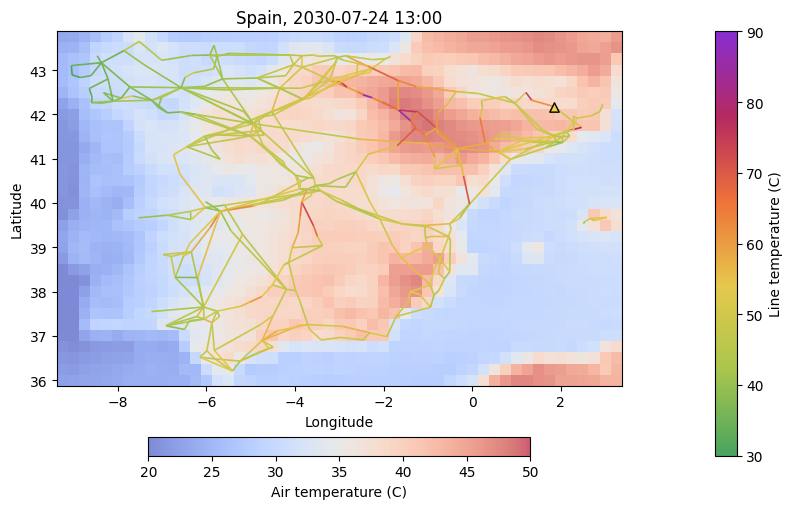

In [2]:
fig, axis = plt.subplots(figsize=(9, 5.2))
weather_artist = axis.pcolormesh(weather.lon, weather.lat, weather.temperature - 273.15,
                cmap="coolwarm", vmin=20, vmax=50, shading="auto", alpha=0.65)
segments = [[(line["lon0"], line["lat0"]), (line["lon1"], line["lat1"])]
            for line in published["lines"]]
line_palette = colours.LinearSegmentedColormap.from_list(
    "line_temperature", ["#48a45f", "#a9c64d", "#e6c84c",
                         "#ee7239", "#b62961", "#872ed0"])
collection = LineCollection(segments, cmap=line_palette,
                            norm=colours.Normalize(30, 90), linewidths=1.2)
collection.set_array(np.array([line["temperature_c"]
                               for line in published["lines"]]))
axis.add_collection(collection)
marked = [bus for bus in published["buses"] if bus["display_marker"]]
axis.scatter([bus["lon"] for bus in marked], [bus["lat"] for bus in marked],
             s=45, marker="^", facecolor="#f5d349", edgecolor="black", zorder=4)
axis.set(xlabel="Longitude", ylabel="Latitude", title="Spain, 2030-07-24 13:00")
axis.set_aspect("equal", adjustable="box")
fig.colorbar(collection, ax=axis, label="Line temperature (C)")
fig.colorbar(weather_artist, ax=axis, orientation="horizontal",
             fraction=0.045, pad=0.12, label="Air temperature (C)")
fig.tight_layout()
plt.show()

## Run the same hour

The runner validates the ten prepared input files before solving, then writes
its result into a temporary directory. Solver round-off may differ slightly
from the saved published record.

In [3]:
from scripts.run_european_example import run_example

with TemporaryDirectory(prefix="heat-analysis-2030-") as directory:
    summary = run_example(bundle, Path(directory) / "run")
    solved = np.load(summary["result_npy"], allow_pickle=True).item()

solved_line_temperature = np.nanmax(solved["con_temp"], axis=1)
published_line_temperature = np.array(
    [line["temperature_c"] for line in published["lines"]])
published_shedding = np.array(
    [bus["load_shedding_mw"] for bus in published["buses"]])
print("Solver status:", summary["solver_status"])
print("Load shedding (MW):", round(float(np.maximum(solved["LS"], 0).sum()), 4))
print("Largest line-temperature difference from published map (C):",
      round(float(np.max(abs(solved_line_temperature - published_line_temperature))), 6))
print("Largest bus-shedding difference from published map (MW):",
      round(float(np.max(abs(solved["LS"] - published_shedding))), 8))

INFO:pypsa.io:Imported network base_s_75_elec.nc has buses, carriers, generators, lines, links, loads, storage_units


Loading EU network from: /private/var/folders/w7/wwh9gvtd2vb45k9vd1_v_tx40000gn/T/heat-analysis-2030-o4cacasn/run/data/EU/networks/base_s_75_elec.nc
RESULTS : success 1 | Demand: 133.96 | Gen: 218.66 | Storage: 56.30 | LS ratio: 0.14 | LS num: 1 | Max temp: 90.00 | Runtime: 1.23s
expr_id: ES_281_td_seg_derate_iter_2_2030-07-24 13:00:00_2024-07-30 00:00:00_storage_0.8_load_growth_1.01_thermal_90
Solver status: 1
Load shedding (MW): 0.1882
Largest line-temperature difference from published map (C): 0.000264
Largest bus-shedding difference from published map (MW): 0.0


The project website offers an interactive view of this same saved 2030
snapshot. Its controls inspect existing values; they do not change the
simulation or re-solve the OPF.